# Predicting 30-day hospital readmission of diabetic patients

**ML Zoomcamp 2026 — Midterm project**

Notebook contents:
1. Data loading and cleaning
2. Exploratory data analysis (EDA)
3. Feature importance analysis
4. Model training and tuning: Logistic Regression, Decision Tree, Random Forest, XGBoost
5. Model selection and final evaluation on the test set

The feature engineering code lives in `features.py` so the notebook, `train.py` and `predict.py` all use the same logic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_score, recall_score, mutual_info_score)
import xgboost as xgb

import features as F

pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid')
SEED = 1

## 1. Data loading

Dataset: [Diabetes 130-US Hospitals for Years 1999–2008](https://archive.ics.uci.edu/dataset/296) (UCI ML Repository, Strack et al. 2014).
Each row is one hospital encounter of a diabetic patient. Missing values are coded as `?`.

In [2]:
raw = F.load_raw('data/diabetic_data.csv')
print(raw.shape)
raw.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
raw.dtypes.value_counts()

str      37
int64    13
Name: count, dtype: int64

In [4]:
print('Unique encounters:', raw['encounter_id'].nunique())
print('Unique patients:  ', raw['patient_nbr'].nunique())

Unique encounters: 101766
Unique patients:   71518


Many patients have more than one encounter. To avoid leakage, the train/validation/test split is done **by patient**, so the same patient never appears in two splits.

### Missing values

,share_missing
weight,0.969
max_glu_serum,0.947
A1Cresult,0.833
medical_specialty,0.491
payer_code,0.396
race,0.022
diag_3,0.014
diag_2,0.004
diag_1,0.000


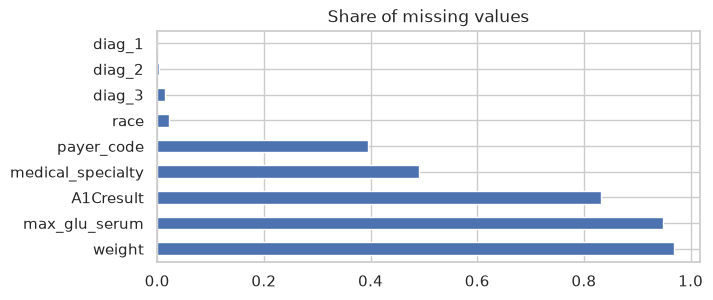

In [5]:
missing = raw.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
display(missing.to_frame('share_missing').round(3))

missing.plot.barh(figsize=(7, 3), title='Share of missing values')
plt.show()

- `weight` (97% missing) is dropped.
- `payer_code` (40% missing) is administrative and not available at discharge in a consistent way, so it is dropped.
- `max_glu_serum` and `A1Cresult` are mostly missing because the **test was not done**; this is information in itself, so missing becomes the category `None`.
- `medical_specialty` (49% missing): missing kept as its own category `Missing`, rare specialties grouped into `Other`.
- `race`: missing → `Unknown`.

### Medication columns with almost no variation

In [6]:
meds = F.ALL_MEDICATIONS
share_no = pd.Series({m: (raw[m] == 'No').mean() for m in meds}).sort_values()
display(share_no.to_frame('share_No').round(4))

,share_No
insulin,0.4656
metformin,0.8036
glipizide,0.8753
glyburide,0.8953
pioglitazone,0.9280
rosiglitazone,0.9375
glimepiride,0.9490
repaglinide,0.9849
glyburide-metformin,0.9931
nateglinide,0.9931


Most of the 23 medication columns are `No` for more than 99% of encounters. Only the 8 most used (`features.MEDICATIONS`) are kept as features;
all of them are summarized by `num_med_changes` (number of dose changes Up/Down during the stay).

### Target variable

`readmitted` has three values: `NO`, `>30` (readmitted after 30 days) and `<30` (readmitted within 30 days).
Hospitals are penalised for **30-day** readmissions, so the target is binary: `readmitted_30 = 1` if `<30`.

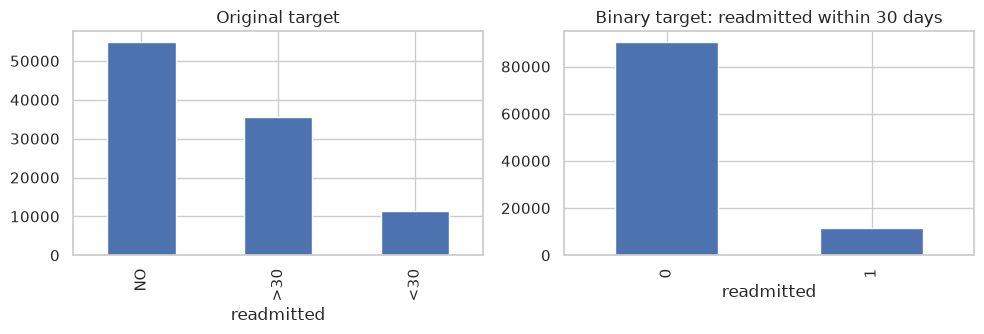

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
raw['readmitted'].value_counts().plot.bar(ax=ax[0], title='Original target')
(raw['readmitted'] == '<30').astype(int).value_counts().plot.bar(ax=ax[1], title='Binary target: readmitted within 30 days')
plt.tight_layout(); plt.show()

### Cleaning

Encounters where the patient died or was discharged to hospice (`discharge_disposition_id` in 11, 13, 14, 19, 20, 21) are removed: these patients cannot be readmitted.
Three rows with gender `Unknown/Invalid` are also removed.

In [8]:
df = F.clean(raw)
print('Rows before:', len(raw), ' after:', len(df))
print('Readmission rate (<30 days): %.3f' % df['readmitted_30'].mean())

Rows before: 101766  after: 99340
Readmission rate (<30 days): 0.114


The classes are **imbalanced** (~11% positives), so accuracy is not a useful metric. Models are compared with **ROC AUC**, and PR AUC (average precision) is also reported.

### Feature engineering

`features.prepare_features` builds the model input:
- `age` bracket `[70-80)` → number `75`
- ID columns (admission type, discharge disposition, admission source) → readable groups (see `data/IDs_mapping.csv`)
- ICD-9 codes `diag_1..3` → 9 disease groups (circulatory, respiratory, diabetes, ...)
- `total_prior_visits` = outpatient + emergency + inpatient visits in the year before
- `num_med_changes` = number of medications whose dose changed

In [9]:
X = F.prepare_features(df)
y = df['readmitted_30'].values
print(X.shape)
X.head()

(99340, 32)


,age_years,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,total_prior_visits,num_med_changes,race,gender,admission_type,discharge_disposition,admission_source,medical_specialty,diag_1_group,diag_2_group,diag_3_group,max_glu_serum,A1Cresult,change,diabetesMed,metformin,repaglinide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,insulin
0,5.0,1.0,41.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,Caucasian,Female,other_or_unknown,other_or_unknown,referral,Other,diabetes,missing,missing,None,None,No,No,No,No,No,No,No,No,No,No
1,15.0,3.0,59.0,0.0,18.0,0.0,0.0,0.0,9.0,0.0,1.0,Caucasian,Female,emergency,home,emergency_room,Missing,other,diabetes,other,None,None,Ch,Yes,No,No,No,No,No,No,No,Up
2,25.0,2.0,11.0,5.0,13.0,2.0,0.0,1.0,6.0,3.0,0.0,AfricanAmerican,Female,emergency,home,emergency_room,Missing,other,diabetes,other,None,None,No,Yes,No,No,No,Steady,No,No,No,No
3,35.0,2.0,44.0,1.0,16.0,0.0,0.0,0.0,7.0,0.0,1.0,Caucasian,Male,emergency,home,emergency_room,Missing,other,diabetes,circulatory,None,None,Ch,Yes,No,No,No,No,No,No,No,Up
4,45.0,1.0,51.0,0.0,8.0,0.0,0.0,0.0,5.0,0.0,0.0,Caucasian,Male,emergency,home,emergency_room,Missing,neoplasms,neoplasms,diabetes,None,None,Ch,Yes,No,No,No,Steady,No,No,No,Steady


In [10]:
X.isna().sum().sum()

np.int64(0)

## 2. Exploratory data analysis

### Numerical features

In [11]:
X[F.NUMERICAL].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age_years,99340.0,65.74,15.95,5.0,55.0,65.0,75.0,95.0
time_in_hospital,99340.0,4.38,2.97,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,99340.0,42.91,19.61,1.0,31.0,44.0,57.0,132.0
num_procedures,99340.0,1.33,1.70,0.0,0.0,1.0,2.0,6.0
num_medications,99340.0,15.98,8.09,1.0,10.0,15.0,20.0,81.0
number_outpatient,99340.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,99340.0,0.20,0.94,0.0,0.0,0.0,0.0,76.0
number_inpatient,99340.0,0.63,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,99340.0,7.40,1.94,1.0,6.0,8.0,9.0,16.0
total_prior_visits,99340.0,1.20,2.29,0.0,0.0,0.0,2.0,80.0


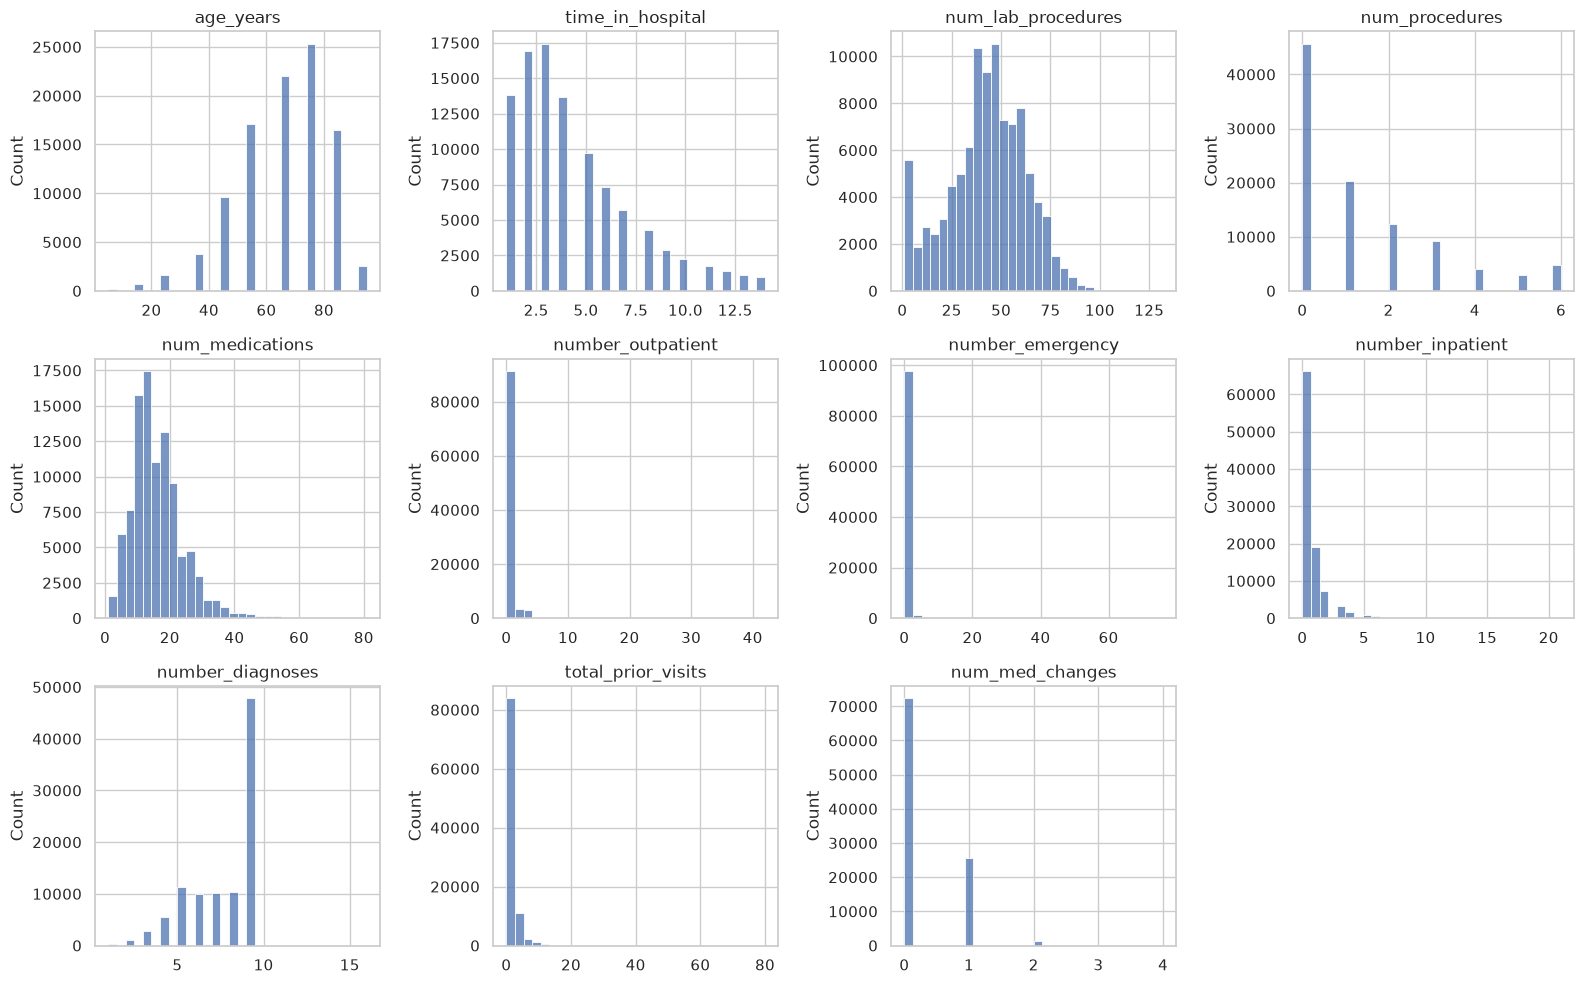

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for col, ax in zip(F.NUMERICAL, axes.flat):
    sns.histplot(X[col], ax=ax, bins=30)
    ax.set_title(col)
    ax.set_xlabel('')
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

The visit counts (`number_outpatient`, `number_emergency`, `number_inpatient`) are very skewed: most patients have 0, a few have 10+.
Tree-based models are not affected by this; for logistic regression the features are standardized through the regularized model and the skew is acceptable.

Readmission rate by number of inpatient visits in the previous year:

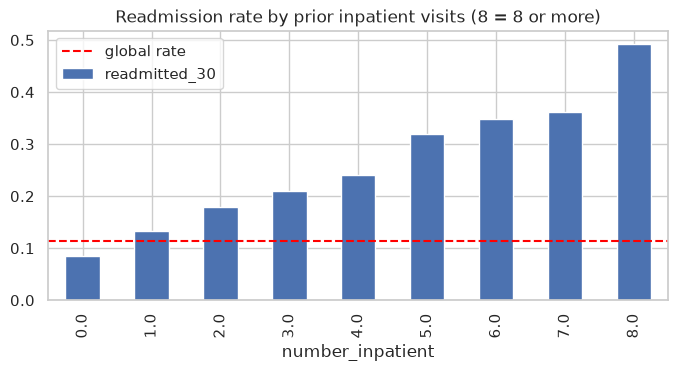

In [13]:
eda = X.copy()
eda['readmitted_30'] = y

inp = eda.assign(number_inpatient=eda['number_inpatient'].clip(upper=8))
ax = inp.groupby('number_inpatient')['readmitted_30'].mean().plot.bar(figsize=(8, 3.5),
        title='Readmission rate by prior inpatient visits (8 = 8 or more)')
ax.axhline(y.mean(), color='red', ls='--', label='global rate'); ax.legend()
plt.show()

Prior hospitalizations are the strongest signal: the readmission rate goes from ~9% with no prior inpatient visits to over 30% with 5 or more.

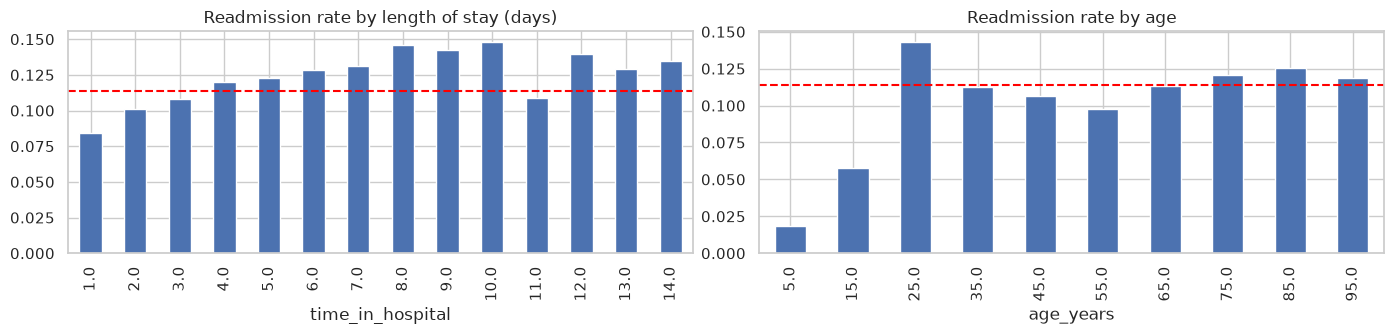

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
eda.groupby('time_in_hospital')['readmitted_30'].mean().plot.bar(ax=axes[0], title='Readmission rate by length of stay (days)')
eda.groupby('age_years')['readmitted_30'].mean().plot.bar(ax=axes[1], title='Readmission rate by age')
for ax in axes: ax.axhline(y.mean(), color='red', ls='--')
plt.tight_layout(); plt.show()

### Correlation between numerical features

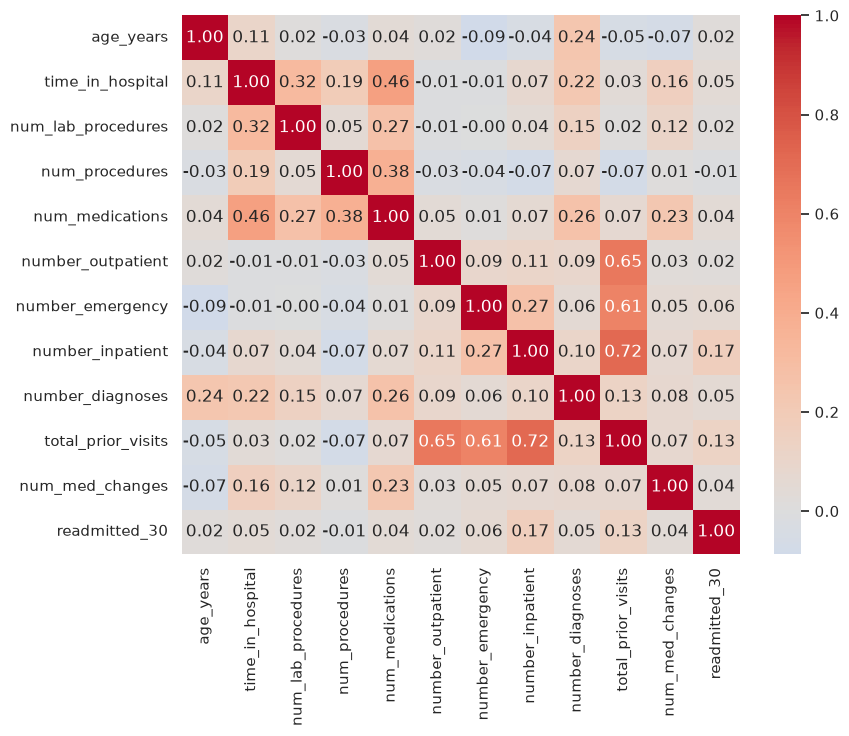

In [15]:
plt.figure(figsize=(9, 7))
sns.heatmap(eda[F.NUMERICAL + ['readmitted_30']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

No pair of input features is extremely correlated except `total_prior_visits` with its components (by construction).

### Categorical features: readmission rate and risk ratio by category

In [16]:
global_rate = y.mean()
for col in ['discharge_disposition', 'admission_source', 'A1Cresult', 'diag_1_group', 'medical_specialty', 'insulin']:
    g = eda.groupby(col)['readmitted_30'].agg(['mean', 'count'])
    g['risk_ratio'] = g['mean'] / global_rate
    display(g.sort_values('risk_ratio', ascending=False).round(3))

,mean,count,risk_ratio
discharge_disposition,,,
other_facility,0.212,5950,1.858
nursing_facility,0.146,14817,1.278
left_ama,0.144,623,1.268
home_health,0.127,13010,1.116
other_or_unknown,0.117,4708,1.031
home,0.093,60232,0.817


,mean,count,risk_ratio
admission_source,,,
emergency_room,0.120,55848,1.052
other_or_unknown,0.108,6874,0.946
referral,0.107,30433,0.941
transfer,0.101,6185,0.884


,mean,count,risk_ratio
A1Cresult,,,
None,0.117,82506,1.026
>7,0.101,3775,0.891
>8,0.099,8137,0.873
Norm,0.098,4922,0.858


,mean,count,risk_ratio
diag_1_group,,,
missing,0.250,20,2.195
diabetes,0.131,8661,1.151
injury,0.124,6851,1.089
circulatory,0.117,29680,1.026
other,0.117,17793,1.026
genitourinary,0.110,5002,0.969
neoplasms,0.109,3131,0.956
digestive,0.108,9333,0.950
respiratory,0.101,13934,0.883


,mean,count,risk_ratio
medical_specialty,,,
Nephrology,0.161,1539,1.415
Family/GeneralPractice,0.121,7252,1.064
Missing,0.118,48614,1.039
InternalMedicine,0.115,14237,1.013
Emergency/Trauma,0.114,7419,1.000
Pulmonology,0.112,854,0.987
Surgery-General,0.112,3059,0.982
Orthopedics,0.108,1392,0.952
Other,0.101,7345,0.885


,mean,count,risk_ratio
insulin,,,
Down,0.142,11908,1.248
Up,0.133,10987,1.171
Steady,0.114,30069,0.999
No,0.102,46376,0.897


Observations:
- Patients discharged to a **nursing facility** or another facility are readmitted more often than those discharged home.
- Patients whose **insulin dose was changed** (`Up`/`Down`) have a higher risk than patients with no insulin.
- Primary diagnosis group and the specialty of the admitting physician also shift the risk (e.g. Nephrology higher; Cardiology and Orthopedics-Reconstructive lower).

## 3. Feature importance analysis

- Categorical features: **mutual information** with the target.
- Numerical features: **ROC AUC of each feature on its own** (as in module 4 of the course) and correlation with the target.

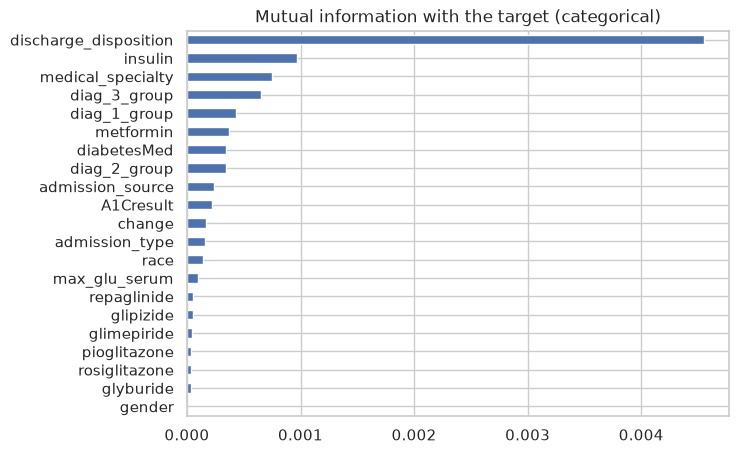

In [17]:
mi = pd.Series({c: mutual_info_score(eda[c], eda['readmitted_30']) for c in F.CATEGORICAL}).sort_values(ascending=False)
mi.plot.barh(figsize=(7, 5), title='Mutual information with the target (categorical)')
plt.gca().invert_yaxis(); plt.show()

In [18]:
num_imp = pd.DataFrame({
    'auc': {c: max(roc_auc_score(y, eda[c]), 1 - roc_auc_score(y, eda[c])) for c in F.NUMERICAL},
    'correlation': eda[F.NUMERICAL].corrwith(eda['readmitted_30']),
}).sort_values('auc', ascending=False)
num_imp.round(3)

,auc,correlation
number_inpatient,0.607,0.168
total_prior_visits,0.604,0.128
time_in_hospital,0.548,0.047
number_diagnoses,0.544,0.054
num_medications,0.544,0.041
number_emergency,0.532,0.061
num_med_changes,0.526,0.036
num_lab_procedures,0.522,0.024
age_years,0.522,0.022
number_outpatient,0.520,0.019


`number_inpatient` / `total_prior_visits` are by far the most informative numerical features, followed by `number_emergency`, `number_diagnoses` and `time_in_hospital`.
Among categoricals, `discharge_disposition` and `diag_1_group` carry the most information. Single-feature signals are weak, so we expect a model AUC around 0.65–0.70, in line with published work on this dataset.

## 4. Train / validation / test split (by patient)

60% / 20% / 20%, grouped by `patient_nbr`.

In [19]:
groups = df['patient_nbr'].values

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
full_train_idx, test_idx = next(gss.split(X, y, groups))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
tr, va = next(gss2.split(X.iloc[full_train_idx], y[full_train_idx], groups[full_train_idx]))
train_idx, val_idx = full_train_idx[tr], full_train_idx[va]

# no patient in more than one split
assert not set(groups[train_idx]) & set(groups[val_idx])
assert not set(groups[full_train_idx]) & set(groups[test_idx])

for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    print(f'{name:5s} {len(idx):6d} rows, positive rate {y[idx].mean():.3f}')

train  59735 rows, positive rate 0.116
val    19797 rows, positive rate 0.108
test   19808 rows, positive rate 0.114


In [20]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(F.to_dicts(X.iloc[train_idx]))
X_val = dv.transform(F.to_dicts(X.iloc[val_idx]))
y_train, y_val = y[train_idx], y[val_idx]
print(X_train.shape, 'one-hot encoded features')

results = []
def evaluate(name, params, y_true, y_pred):
    r = {'model': name, 'params': params,
         'roc_auc': roc_auc_score(y_true, y_pred),
         'pr_auc': average_precision_score(y_true, y_pred)}
    results.append(r)
    return r

(59735, 120) one-hot encoded features


## 5. Model training and tuning

### 5.1 Logistic regression (baseline) — tuning `C`

Numerical features are standardized for logistic regression.

In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

for C in [0.001, 0.01, 0.1, 1, 10]:
    lr = LogisticRegression(C=C, max_iter=2000, class_weight='balanced')
    lr.fit(X_train_s, y_train)
    r = evaluate('logistic_regression', {'C': C}, y_val, lr.predict_proba(X_val_s)[:, 1])
    print(f"C={C:<6} AUC={r['roc_auc']:.4f}  PR-AUC={r['pr_auc']:.4f}")

C=0.001  AUC=0.6541  PR-AUC=0.1951
C=0.01   AUC=0.6538  PR-AUC=0.1952


C=0.1    AUC=0.6538  PR-AUC=0.1952


C=1      AUC=0.6537  PR-AUC=0.1951


C=10     AUC=0.6537  PR-AUC=0.1950


### 5.2 Decision tree — tuning `max_depth` and `min_samples_leaf`

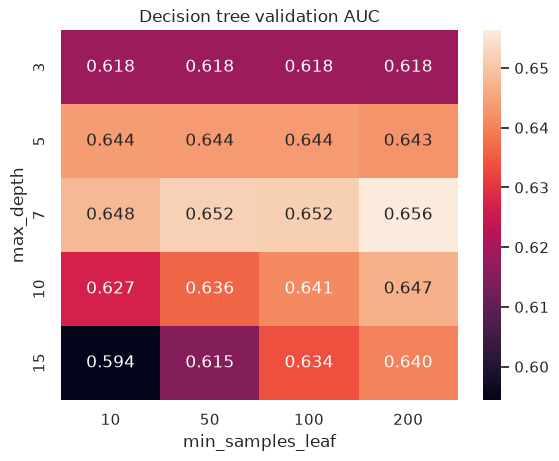

In [22]:
dt_scores = []
for depth in [3, 5, 7, 10, 15]:
    for leaf in [10, 50, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED)
        dt.fit(X_train, y_train)
        r = evaluate('decision_tree', {'max_depth': depth, 'min_samples_leaf': leaf}, y_val, dt.predict_proba(X_val)[:, 1])
        dt_scores.append((depth, leaf, r['roc_auc']))

dt_scores = pd.DataFrame(dt_scores, columns=['max_depth', 'min_samples_leaf', 'auc'])
sns.heatmap(dt_scores.pivot(index='max_depth', columns='min_samples_leaf', values='auc'), annot=True, fmt='.3f')
plt.title('Decision tree validation AUC'); plt.show()

### 5.3 Random forest — tuning `max_depth`, `min_samples_leaf`, `n_estimators`

In [23]:
rf_scores = []
for depth in [10, 15, 20]:
    for leaf in [5, 20, 50]:
        rf = RandomForestClassifier(n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
                                    n_jobs=-1, random_state=SEED)
        rf.fit(X_train, y_train)
        r = evaluate('random_forest', {'n_estimators': 200, 'max_depth': depth, 'min_samples_leaf': leaf},
                     y_val, rf.predict_proba(X_val)[:, 1])
        rf_scores.append((depth, leaf, r['roc_auc']))
        print(f"depth={depth} leaf={leaf} AUC={r['roc_auc']:.4f}")

rf_scores = pd.DataFrame(rf_scores, columns=['max_depth', 'min_samples_leaf', 'auc'])
best_rf = rf_scores.sort_values('auc').iloc[-1]
print('best:', best_rf.to_dict())

depth=10 leaf=5 AUC=0.6608


depth=10 leaf=20 AUC=0.6589


depth=10 leaf=50 AUC=0.6587


depth=15 leaf=5 AUC=0.6629


depth=15 leaf=20 AUC=0.6616


depth=15 leaf=50 AUC=0.6618


depth=20 leaf=5 AUC=0.6604


depth=20 leaf=20 AUC=0.6620


depth=20 leaf=50 AUC=0.6626
best: {'max_depth': 15.0, 'min_samples_leaf': 5.0, 'auc': 0.6629369617602593}


In [24]:
# effect of the number of trees with the best depth / leaf
for n in [50, 100, 300, 500]:
    rf = RandomForestClassifier(n_estimators=n, max_depth=int(best_rf.max_depth),
                                min_samples_leaf=int(best_rf.min_samples_leaf), n_jobs=-1, random_state=SEED)
    rf.fit(X_train, y_train)
    r = evaluate('random_forest', {'n_estimators': n, 'max_depth': int(best_rf.max_depth),
                                   'min_samples_leaf': int(best_rf.min_samples_leaf)},
                 y_val, rf.predict_proba(X_val)[:, 1])
    print(f"n_estimators={n} AUC={r['roc_auc']:.4f}")

n_estimators=50 AUC=0.6612


n_estimators=100 AUC=0.6617


n_estimators=300 AUC=0.6622


n_estimators=500 AUC=0.6621


### 5.4 XGBoost — tuning `eta`, `max_depth`, `min_child_weight`

Number of boosting rounds is chosen with early stopping on the validation set.

In [25]:
features_names = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features_names)

def train_xgb(eta, max_depth, min_child_weight, num_rounds=1000):
    params = {'eta': eta, 'max_depth': max_depth, 'min_child_weight': min_child_weight,
              'objective': 'binary:logistic', 'eval_metric': 'auc',
              'subsample': 0.8, 'colsample_bytree': 0.8, 'nthread': 2, 'seed': SEED}
    evals_result = {}
    model = xgb.train(params, dtrain, num_boost_round=num_rounds, evals=[(dtrain, 'train'), (dval, 'val')],
                      early_stopping_rounds=50, evals_result=evals_result, verbose_eval=False)
    return model, evals_result

for eta in [0.3, 0.1, 0.05]:
    model, res = train_xgb(eta, 6, 1)
    print(f"eta={eta}: best AUC={model.best_score:.4f} at round {model.best_iteration}")

eta=0.3: best AUC=0.6614 at round 13


eta=0.1: best AUC=0.6655 at round 43


eta=0.05: best AUC=0.6654 at round 90


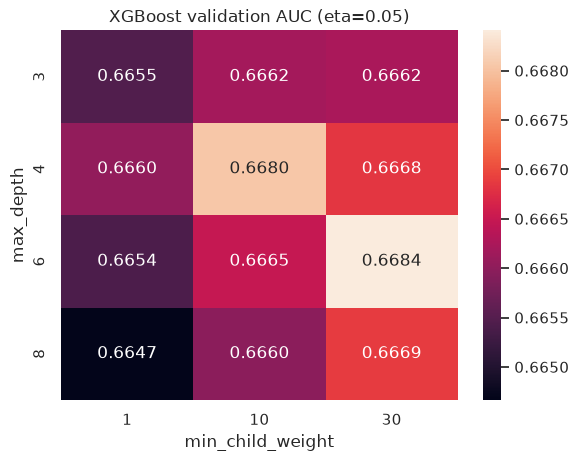

,max_depth,min_child_weight,auc,rounds
8,6,30,0.668408,207
4,4,10,0.668047,221
11,8,30,0.666880,124
5,4,30,0.666830,201
7,6,10,0.666483,124


In [26]:
xgb_scores = []
for max_depth in [3, 4, 6, 8]:
    for mcw in [1, 10, 30]:
        model, _ = train_xgb(0.05, max_depth, mcw)
        y_pred = model.predict(dval, iteration_range=(0, model.best_iteration + 1))
        r = evaluate('xgboost', {'eta': 0.05, 'max_depth': max_depth, 'min_child_weight': mcw,
                                 'num_rounds': model.best_iteration + 1}, y_val, y_pred)
        xgb_scores.append((max_depth, mcw, r['roc_auc'], model.best_iteration + 1))

xgb_scores = pd.DataFrame(xgb_scores, columns=['max_depth', 'min_child_weight', 'auc', 'rounds'])
sns.heatmap(xgb_scores.pivot(index='max_depth', columns='min_child_weight', values='auc'), annot=True, fmt='.4f')
plt.title('XGBoost validation AUC (eta=0.05)'); plt.show()
xgb_scores.sort_values('auc', ascending=False).head()

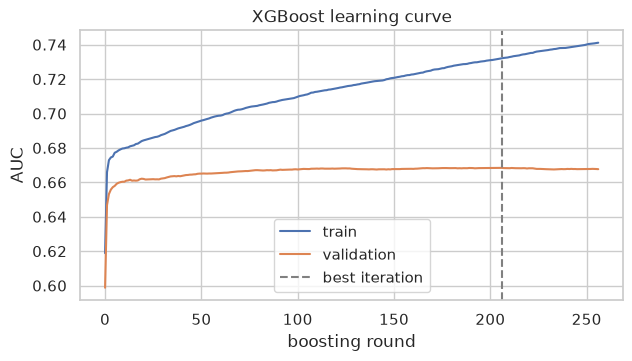

In [27]:
best_xgb = xgb_scores.sort_values('auc').iloc[-1]
model, res = train_xgb(0.05, int(best_xgb.max_depth), int(best_xgb.min_child_weight))
plt.figure(figsize=(7, 3.5))
plt.plot(res['train']['auc'], label='train'); plt.plot(res['val']['auc'], label='validation')
plt.axvline(model.best_iteration, color='grey', ls='--', label='best iteration')
plt.xlabel('boosting round'); plt.ylabel('AUC'); plt.legend(); plt.title('XGBoost learning curve'); plt.show()

## 6. Model comparison and selection

In [28]:
res_df = pd.DataFrame(results)
best_per_model = res_df.loc[res_df.groupby('model')['roc_auc'].idxmax()].sort_values('roc_auc', ascending=False)
best_per_model[['model', 'params', 'roc_auc', 'pr_auc']].round(4)

,model,params,roc_auc,pr_auc
46,xgboost,"{'eta': 0.05, 'max_depth': 6, 'min_child_weigh...",0.6684,0.2051
28,random_forest,"{'n_estimators': 200, 'max_depth': 15, 'min_sa...",0.6629,0.2042
16,decision_tree,"{'max_depth': 7, 'min_samples_leaf': 200}",0.6563,0.1920
0,logistic_regression,{'C': 0.001},0.6541,0.1951


XGBoost gives the best validation ROC AUC and PR AUC, so it is selected as the final model.

### Final evaluation on the test set

The final model is trained on train + validation with the selected parameters and evaluated once on the held-out test set.

In [29]:
best = res_df[res_df.model == 'xgboost'].sort_values('roc_auc').iloc[-1]['params']
print('Selected parameters:', best)

dv_full = DictVectorizer(sparse=False)
X_full = dv_full.fit_transform(F.to_dicts(X.iloc[full_train_idx]))
X_test = dv_full.transform(F.to_dicts(X.iloc[test_idx]))
y_full, y_test = y[full_train_idx], y[test_idx]

final_params = {'eta': best['eta'], 'max_depth': best['max_depth'], 'min_child_weight': best['min_child_weight'],
                'objective': 'binary:logistic', 'eval_metric': 'auc',
                'subsample': 0.8, 'colsample_bytree': 0.8, 'nthread': 2, 'seed': SEED}
names = list(dv_full.get_feature_names_out())
final_model = xgb.train(final_params, xgb.DMatrix(X_full, label=y_full, feature_names=names),
                        num_boost_round=int(best['num_rounds']))
y_test_pred = final_model.predict(xgb.DMatrix(X_test, feature_names=names))
print('Test ROC AUC: %.4f' % roc_auc_score(y_test, y_test_pred))
print('Test PR AUC:  %.4f (baseline = positive rate %.3f)' % (average_precision_score(y_test, y_test_pred), y_test.mean()))

Selected parameters: {'eta': 0.05, 'max_depth': 6, 'min_child_weight': 30, 'num_rounds': 207}


Test ROC AUC: 0.6698
Test PR AUC:  0.2168 (baseline = positive rate 0.114)


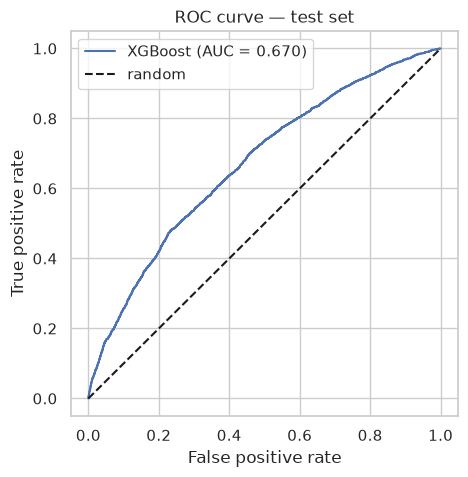

In [30]:
fpr, tpr, _ = roc_curve(y_test, y_test_pred)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label='XGBoost (AUC = %.3f)' % roc_auc_score(y_test, y_test_pred))
plt.plot([0, 1], [0, 1], 'k--', label='random')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); plt.title('ROC curve — test set'); plt.show()

### Choosing a decision threshold

The model output is a risk score. A hospital can only follow up with a limited number of patients, so the threshold sets the trade-off between
how many patients are flagged and how many future readmissions are caught (recall).

In [31]:
rows = []
for t in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4]:
    flagged = y_test_pred >= t
    rows.append({'threshold': t, 'share_flagged': flagged.mean(),
                 'precision': precision_score(y_test, flagged), 'recall': recall_score(y_test, flagged)})
pd.DataFrame(rows).round(3)

,threshold,share_flagged,precision,recall
0,0.10,0.477,0.165,0.689
1,0.15,0.206,0.217,0.393
2,0.20,0.093,0.258,0.210
3,0.25,0.047,0.313,0.128
4,0.30,0.025,0.343,0.075
5,0.40,0.007,0.413,0.025


With a threshold of **0.10**, about half of the patients are flagged and they include ~70% of all 30-day readmissions. With **0.15**, about 1 in 5 patients is flagged, catching ~40% of readmissions with a precision almost twice the base rate (0.22 vs 0.11).
The service returns the probability plus a risk level (`low` < 0.10 ≤ `medium` < 0.20 ≤ `high`) so each hospital can pick its own cut-off.

### Feature importance of the final model

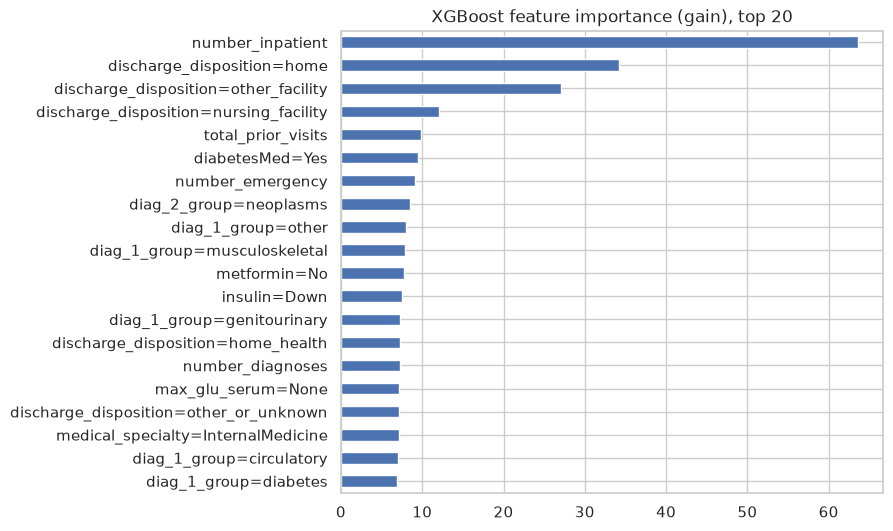

In [32]:
imp = pd.Series(final_model.get_score(importance_type='gain')).sort_values(ascending=False).head(20)
imp.plot.barh(figsize=(7, 6), title='XGBoost feature importance (gain), top 20')
plt.gca().invert_yaxis(); plt.show()

## Conclusions

- Prior inpatient visits, discharge destination (home vs. another facility) and prior emergency visits are the main drivers of 30-day readmission, followed by the diagnosis groups.
- Predicting readmission from administrative/clinical encounter data is hard: the best model (XGBoost) reaches a test ROC AUC of about 0.67, in line with published results on this dataset. It is still useful for **ranking** patients so that follow-up resources go to the riskiest ones first.
- The training logic is exported to `train.py`; the model is served by `predict.py` (FastAPI) in a Docker container and deployed to Kubernetes (see `README.md`).